# 08 · Visualisation and interactive dashboard

**Guideline covered:** Visualization

**What this notebook does.**
1. **Presentation charts (cell 9a):** theme heatmap of specific complaints (static and interactive HTML), model comparison, the Paytm 10.84.5 release event and company replies. One fixed colour per app is used throughout.
2. **Dashboard data (cell D5):** builds the data for the dashboard (personal details masked) and the statistical-test tables, including the emerging-topics test (chi-square per app and theme, Bonferroni-corrected).
3. **Dashboard (cell D6):** writes the Streamlit app ([`dashboard/app.py`](../dashboard/app.py)) with nine views: Overview, Trends, Complaint themes, Fix priorities (with a "what if we fixed it" calculator), Releases (with a live release investigator), Emerging topics, Company replies, Models & tests, and Review explorer.
4. **Automated test (cell D7):** runs the dashboard headlessly with different filters and clicks; no errors.

The first code cell is a small setup cell, added so that this notebook can run on its own (it was originally run directly after notebook 07).

**Inputs:** processed data and result tables · **Outputs:** figures 11–14, `dashboard/` folder, statistical-test tables

**How to run:** open in Google Colab, keep the project folder at `MyDrive/upi-complaint-analytics` (or change `BASE` in the first code cell) and run the cells from top to bottom. The outputs shown are from the original run.

## Setup

In [ ]:
# Setup (added for running this notebook on its own; originally it ran straight after notebook 07).
# Reloads the objects that cell 9a below expects in memory.
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC, REP = f'{BASE}/data/processed', f'{BASE}/reports'
apps = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
rev = pd.read_parquet(f'{PROC}/reviews_with_sentiment.parquet')
themes_cmp = pd.read_parquet(f'{PROC}/complaints_with_themes.parquet')[['review_id', 'theme']]
TARGET = '10.84.5'
summ = pd.read_csv(f'{REP}/paytm_event_groups.csv').set_index('group')   # written by cell D5
replies = pd.read_csv(f'{REP}/reply_analysis.csv', index_col=0)

## Phase 9a: presentation charts

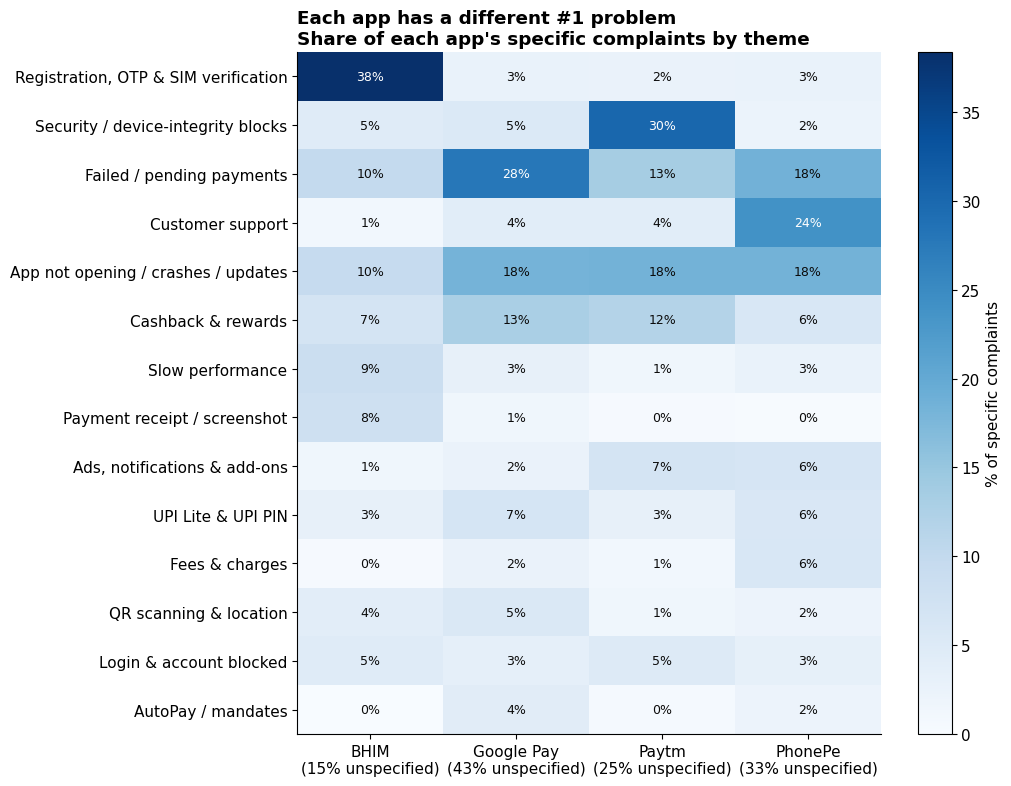

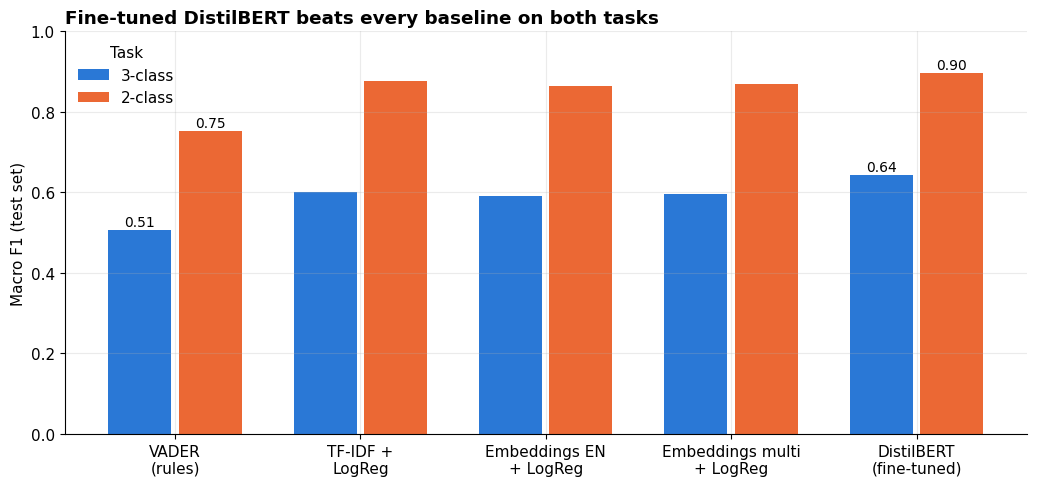

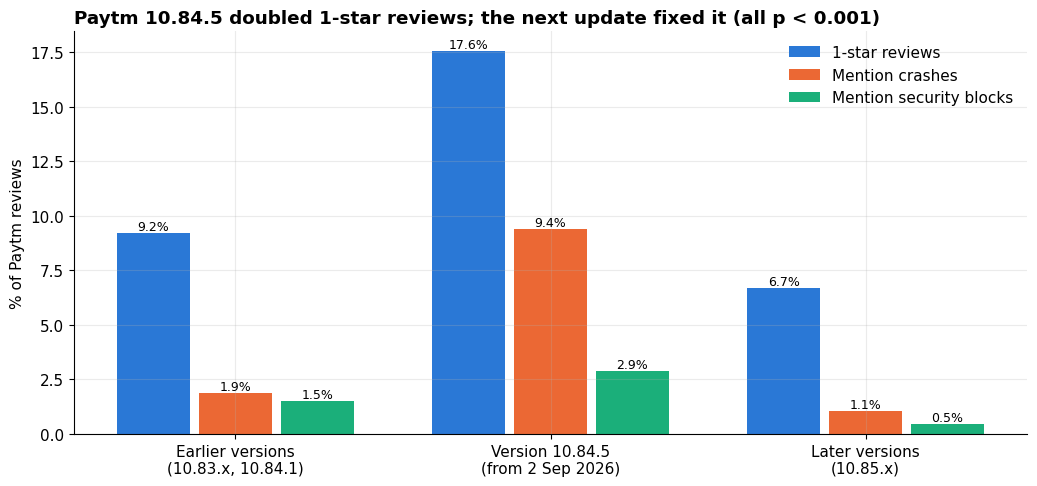

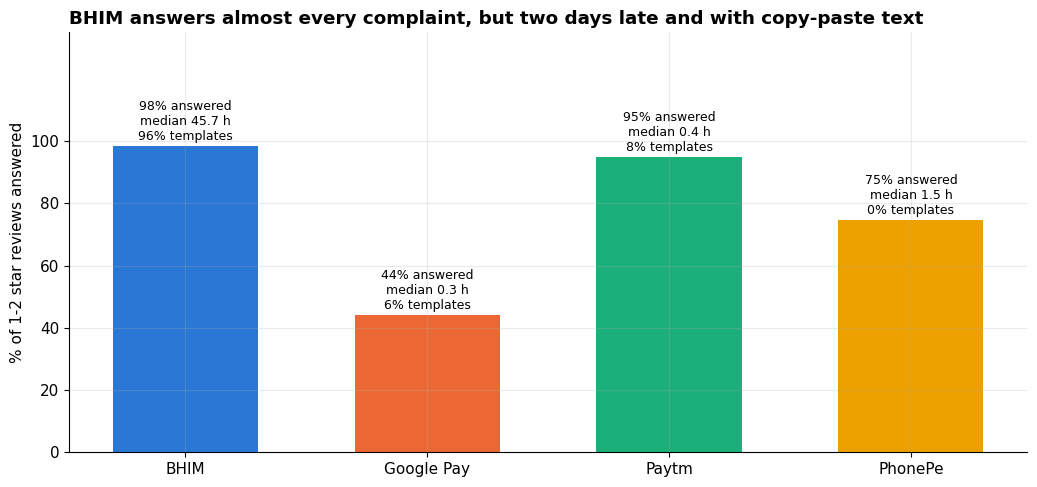

['01_rating_distribution.png', '02_length_by_rating.png', '03_weekly_trends.png', '07_theme_heatmap.png', '08_themes_over_time.png', '09_rating_drivers.png', '10_priority_matrix.png', '11_theme_heatmap_specific.html', '11_theme_heatmap_specific.png', '12_model_comparison.png', '13_paytm_release_event.png', '14_complaint_replies.png']


In [ ]:
# ===== Phase 9a – Final presentation charts (PNG for slides + interactive HTML) =====
# One fixed colour per app everywhere (colour-blind-checked palette); one hue light-to-dark for magnitudes.
!pip install -q plotly
import plotly.express as px
FIG = f'{BASE}/reports/figures'
APP_COLORS = {'BHIM': '#2a78d6', 'Google Pay': '#eb6834', 'Paytm': '#1baf7a', 'PhonePe': '#eda100'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'font.size': 11, 'axes.titleweight': 'bold'})

# 1) Theme heatmap of SPECIFIC complaints; the unspecified share is shown under each app name
tc = themes_cmp.merge(rev[['review_id', 'app']], on='review_id')
gen = (tc.theme == 'General dissatisfaction').groupby(tc.app).mean().mul(100)
spec = tc[tc.theme != 'General dissatisfaction']
hm = pd.crosstab(spec.theme, spec.app, normalize='columns').mul(100)[apps]
hm = hm.loc[hm.max(1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10.5, 8))
im = ax.imshow(hm.values, cmap='Blues', aspect='auto', vmin=0)
ax.set_xticks(range(4)); ax.set_xticklabels([f'{a}\n({gen[a]:.0f}% unspecified)' for a in apps])
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index); ax.grid(False)
for i in range(hm.shape[0]):
    for j in range(4):
        v = hm.values[i, j]
        ax.text(j, i, f'{v:.0f}%', ha='center', va='center', fontsize=9, color='white' if v > 20 else '#0b0b0b')
ax.set_title("Each app has a different #1 problem\nShare of each app's specific complaints by theme", loc='left')
plt.colorbar(im, ax=ax, label='% of specific complaints'); plt.tight_layout()
plt.savefig(f'{FIG}/11_theme_heatmap_specific.png', dpi=200); plt.show()
px.imshow(hm.round(1), text_auto=True, color_continuous_scale='Blues', aspect='auto',
          title="Share of each app's specific complaints by theme (%)").write_html(f'{FIG}/11_theme_heatmap_specific.html')

# 2) Model comparison (macro F1 on the test set)
res = pd.read_csv(f'{BASE}/reports/model_results.csv')
order = ['VADER', 'TF-IDF + LogReg', 'Embeddings MiniLM-en + LogReg', 'Embeddings MiniLM-multilingual + LogReg', 'DistilBERT (fine-tuned)']
short = ['VADER\n(rules)', 'TF-IDF +\nLogReg', 'Embeddings EN\n+ LogReg', 'Embeddings multi\n+ LogReg', 'DistilBERT\n(fine-tuned)']
piv = res.pivot(index='model', columns='task', values='macro_f1').loc[order]
x, w = np.arange(len(order)), 0.38
fig, ax = plt.subplots(figsize=(10.5, 5))
for k, (task, col) in enumerate([('3-class', '#2a78d6'), ('2-class', '#eb6834')]):
    bars = ax.bar(x + (k - 0.5) * w, piv[task], w - 0.04, color=col, label=task)
    for i in [0, len(order) - 1]:                      # label only the first and the best model
        ax.text(bars[i].get_x() + bars[i].get_width() / 2, piv[task].iloc[i] + 0.01, f'{piv[task].iloc[i]:.2f}', ha='center', fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(short); ax.set_ylim(0, 1); ax.set_ylabel('Macro F1 (test set)')
ax.set_title('Fine-tuned DistilBERT beats every baseline on both tasks', loc='left'); ax.legend(title='Task', frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/12_model_comparison.png', dpi=200); plt.show()

# 3) Paytm version 10.84.5 event
pv = summ.loc[['earlier versions', TARGET, 'later versions'], ['pct_1_star', 'pct_crash_mention', 'pct_security_mention']]
pv.columns = ['1-star reviews', 'Mention crashes', 'Mention security blocks']
fig, ax = plt.subplots(figsize=(10.5, 5))
x, w = np.arange(3), 0.26
for k, (c, col) in enumerate(zip(pv.columns, ['#2a78d6', '#eb6834', '#1baf7a'])):
    bars = ax.bar(x + (k - 1) * w, pv[c], w - 0.03, color=col, label=c)
    ax.bar_label(bars, fmt='%.1f%%', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(['Earlier versions\n(10.83.x, 10.84.1)', 'Version 10.84.5\n(from 2 Sep 2026)', 'Later versions\n(10.85.x)'])
ax.set_ylabel('% of Paytm reviews'); ax.legend(frameon=False)
ax.set_title('Paytm 10.84.5 doubled 1-star reviews; the next update fixed it (all p < 0.001)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/13_paytm_release_event.png', dpi=200); plt.show()

# 4) Replies to complaints
rp = replies.loc[apps]
fig, ax = plt.subplots(figsize=(10.5, 5))
bars = ax.bar(apps, rp['reply_rate_1_2_star_%'], color=[APP_COLORS[a] for a in apps], width=0.6)
for b, a in zip(bars, apps):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 2,
            f"{rp.loc[a, 'reply_rate_1_2_star_%']:.0f}% answered\nmedian {rp.loc[a, 'median_hours_1_2_star']:.1f} h\n{rp.loc[a, 'template_share_1_2_star_%']:.0f}% templates",
            ha='center', fontsize=9)
ax.set_ylim(0, 135); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel('% of 1-2 star reviews answered')
ax.set_title('BHIM answers almost every complaint, but two days late and with copy-paste text', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/14_complaint_replies.png', dpi=200); plt.show()
print(sorted(os.listdir(FIG)) if 'os' in dir() else 'saved')

## Phase 9c: dashboard data and statistical-test tables (cell D5)

In [2]:
# ===== Phase 9c – Dashboard v2: richer data and statistical-test tables =====
# Cell D5: builds everything the new dashboard needs, in the dashboard folder (and the new tables in reports/).
#  - review data with theme mentions, template-reply flag, personal details masked, no review IDs
#  - Paytm 10.84.5 tests (V1), crash robustness check (C1), emerging topics with chi-square tests (new)
#  - one summary table of every statistical test in the project
import os, re, shutil, numpy as np, pandas as pd, statsmodels.formula.api as smf
from scipy import stats
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC, REP, DASH = f'{BASE}/data/processed', f'{BASE}/reports', f'{BASE}/dashboard'
os.makedirs(DASH, exist_ok=True)
APPS = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']

rev = pd.read_parquet(f'{PROC}/reviews_with_sentiment.parquet')
rev = rev.merge(pd.read_parquet(f'{PROC}/theme_mentions.parquet'), on='review_id', how='left')
themes_cmp = pd.read_parquet(f'{PROC}/complaints_with_themes.parquet')[['review_id', 'theme', 'review_date', 'app']]
MCOLS = [c for c in rev.columns if c.startswith('m_') and c != 'm_crash_strict']
rev[MCOLS] = rev[MCOLS].fillna(0).astype('int8')
rev['log_words'] = np.log1p(rev.n_words)

# --- 1. Paytm 10.84.5 event (same tests as cell V1), saved as a table
TARGET = '10.84.5'
p = rev[(rev.app == 'Paytm') & rev.app_version.notna()].copy()
fs = p.groupby('app_version').review_date.min()
p['group'] = np.where(p.app_version == TARGET, TARGET,
                      np.where(p.app_version.map(fs) < fs[TARGET], 'earlier versions', 'later versions'))
ev = []
for g in ['earlier versions', TARGET, 'later versions']:
    s = p[p.group == g]
    ev.append({'group': g, 'reviews': len(s), 'avg_rating': round(s.rating.mean(), 2),
               'pct_1_star': round((s.rating == 1).mean() * 100, 1),
               'pct_crash_mention': round(s.m_crash.mean() * 100, 1),
               'pct_security_mention': round(s.m_security.mean() * 100, 1)})
def two_tests(a, b):
    A, B = p[p.group == a], p[p.group == b]
    chi = lambda col: stats.chi2_contingency([[A[col].sum(), len(A) - A[col].sum()], [B[col].sum(), len(B) - B[col].sum()]])[1]
    A, B = A.assign(one=(A.rating == 1).astype(int)), B.assign(one=(B.rating == 1).astype(int))
    p1 = stats.chi2_contingency([[A.one.sum(), len(A) - A.one.sum()], [B.one.sum(), len(B) - B.one.sum()]])[1]
    return {'ratings_mann_whitney_p': stats.mannwhitneyu(A.rating, B.rating).pvalue,
            'one_star_chi2_p': p1, 'crash_chi2_p': chi('m_crash'), 'security_chi2_p': chi('m_security')}
tests_ev = {'earlier vs 10.84.5': two_tests('earlier versions', TARGET), '10.84.5 vs later': two_tests(TARGET, 'later versions')}
paytm_groups = pd.DataFrame(ev)
LABEL = {'ratings_mann_whitney_p': ('Star ratings', 'Mann-Whitney U'), 'one_star_chi2_p': ('Share of 1-star reviews', 'Chi-square'),
         'crash_chi2_p': ('Share mentioning crashes', 'Chi-square'), 'security_chi2_p': ('Share mentioning security blocks', 'Chi-square')}
paytm_tests = pd.DataFrame([{'comparison': name, 'measure': LABEL[k][0], 'test': LABEL[k][1], 'p_value': f'{v:.1e}'}
                            for name, t in tests_ev.items() for k, v in t.items()])

# --- 2. Robustness: crash effect with stricter keywords (same as cell C1)
strict = r"not open|crash|clos(e|es|ed|ing) (automatically|itself|suddenly)|getting closed|gets closed|stopped working|not responding|\bhang|freez|glitch|disappear|after (the |this |latest )?update|new update|not updat"
rev['m_crash_strict'] = rev.text_light.str.contains(strict, regex=True).astype(int)
cols2 = [c for c in MCOLS if c != 'm_crash'] + ['m_crash_strict']
rob = []
o1 = smf.ols('rating ~ ' + ' + '.join(MCOLS) + ' + log_words + C(app)', data=rev).fit(cov_type='HC3')
o2 = smf.ols('rating ~ ' + ' + '.join(cols2) + ' + log_words + C(app)', data=rev).fit(cov_type='HC3')
rob.append({'scope': 'All apps', 'broad_effect': round(o1.params['m_crash'], 3), 'broad_mention_%': round(rev.m_crash.mean() * 100, 2),
            'strict_effect': round(o2.params['m_crash_strict'], 3), 'strict_p': round(o2.pvalues['m_crash_strict'], 4),
            'strict_mention_%': round(rev.m_crash_strict.mean() * 100, 2)})
for a in APPS:
    d = rev[rev.app == a]
    m1 = smf.ols('rating ~ ' + ' + '.join(MCOLS) + ' + log_words', data=d).fit(cov_type='HC3')
    m2 = smf.ols('rating ~ ' + ' + '.join(cols2) + ' + log_words', data=d).fit(cov_type='HC3')
    rob.append({'scope': a, 'broad_effect': round(m1.params['m_crash'], 3), 'broad_mention_%': round(d.m_crash.mean() * 100, 2),
                'strict_effect': round(m2.params['m_crash_strict'], 3), 'strict_p': round(m2.pvalues['m_crash_strict'], 4),
                'strict_mention_%': round(d.m_crash_strict.mean() * 100, 2)})
rob = pd.DataFrame(rob)

# --- 3. Emerging topics: last 4 weeks vs earlier, chi-square per app and theme, Bonferroni-corrected (new test)
d = themes_cmp.copy()
d['review_date'] = pd.to_datetime(d.review_date)
d['last'] = d.review_date > d.groupby('app').review_date.transform('max') - pd.Timedelta(days=28)
em = []
for (a, th), _ in d.groupby(['app', 'theme']):
    A = d[d.app == a]
    x1, n1 = int(((A.theme == th) & A['last']).sum()), int(A['last'].sum())
    x0, n0 = int(((A.theme == th) & ~A['last']).sum()), int((~A['last']).sum())
    if x1 < 20:
        continue
    em.append({'app': a, 'theme': th, 'earlier_%': round(x0 / n0 * 100, 1), 'last_4_weeks_%': round(x1 / n1 * 100, 1),
               'change_pp': round((x1 / n1 - x0 / n0) * 100, 1), 'complaints_last_4_weeks': x1,
               'p_value': stats.chi2_contingency([[x1, n1 - x1], [x0, n0 - x0]])[1]})
em = pd.DataFrame(em)
em['significant'] = em.p_value < 0.05 / len(em)
em = em.sort_values('change_pp', ascending=False)

# --- 4. One table of every statistical test in the project
drv = pd.read_csv(f'{REP}/rating_drivers_all_apps.csv')
mon = pd.read_csv(f'{REP}/release_monitor.csv')
worse = mon[mon.significant & (mon['diff'] < 0)]
fmt = lambda x: f'{x:.1e}'
summary = pd.DataFrame([
    {'test': 'OLS regression, HC3 robust errors', 'where': 'Cell M2', 'question': 'How many stars does a review lose when it mentions each problem (all apps, controlling for app and review length)?',
     'result': f"{(drv.p_value < 0.05).sum()} of {len(drv)} themes significant; largest: AutoPay {drv.stars_effect.min():.2f} stars. Not significant: "
               + ', '.join(drv[drv.p_value >= 0.05].theme)},
    {'test': 'OLS regression per app, HC3', 'where': 'Cell M3', 'question': 'Which problems cost each app the most stars, and what would fixing them gain?',
     'result': 'BHIM registration/OTP/SIM: -0.99 stars, potential gain +0.18 stars (largest)'},
    {'test': 'Mann-Whitney U', 'where': 'Cell V1', 'question': 'Were Paytm 10.84.5 ratings different from earlier and later versions?',
     'result': f"earlier vs 10.84.5 p = {fmt(tests_ev['earlier vs 10.84.5']['ratings_mann_whitney_p'])}; 10.84.5 vs later p = {fmt(tests_ev['10.84.5 vs later']['ratings_mann_whitney_p'])}"},
    {'test': 'Chi-square', 'where': 'Cell V1', 'question': 'Did the share of 1-star reviews, crash and security mentions change with Paytm 10.84.5?',
     'result': f"1-star 9.2% -> 17.6% -> 6.7%; all p < {max(v for t in tests_ev.values() for v in t.values()):.0e}"},
    {'test': 'Mann-Whitney U + Bonferroni', 'where': 'Cell V2', 'question': f'Which of {len(mon)} versions (300+ reviews) were rated differently from the rest of their app?',
     'result': f"{len(worse)} significantly worse: " + ', '.join(worse.app + ' ' + worse.version.str.replace(r' \(.*\)', '', regex=True))},
    {'test': 'OLS regression (robustness)', 'where': 'Cell C1', 'question': 'Does the crash effect survive without the vague phrase "not working"?',
     'result': f"Yes: {rob.broad_effect.iloc[0]:.2f} -> {rob.strict_effect.iloc[0]:.2f} stars, still significant"},
    {'test': 'Chi-square + Bonferroni', 'where': 'Cell D5', 'question': 'Which complaint themes grew or shrank in the last 4 weeks?',
     'result': f"{em.significant.sum()} of {len(em)} changes significant; rising: "
               + ', '.join((em[em.significant & (em.change_pp > 0)].app + ' ' + em[em.significant & (em.change_pp > 0)].theme).head(4))},
])

# --- 5. Dashboard data: masked texts, theme mentions, template flag; no review IDs
EMAIL = re.compile(r'[\w.+-]+@[\w-]+(?:\.[\w-]+)*')
PHONE = re.compile(r'(?<!\d)(?:\+?91[\s-]?)?[6-9]\d{4}[\s-]?\d{5}(?!\d)')
LONGNUM = re.compile(r'(?<!\d)\d{11,18}(?!\d)')
def mask(t):
    if not isinstance(t, str):
        return t
    return LONGNUM.sub('[number]', PHONE.sub('[phone]', EMAIL.sub('[email/UPI ID]', t)))
dash = rev[['review_id', 'app', 'review_date', 'rating', 'review_text', 'bert_label', 'app_version', 'helpful_votes',
            'company_reply', 'reply_date'] + MCOLS].merge(themes_cmp[['review_id', 'theme']], on='review_id', how='left')
dash['is_complaint'] = (dash.rating <= 2) | (dash.bert_label == 'negative')
dash['replied'] = dash.company_reply.notna()
dash['template'] = dash.company_reply.map(dash.company_reply.value_counts()).fillna(0) >= 20
dash['reply_hours'] = ((pd.to_datetime(dash.reply_date) - pd.to_datetime(dash.review_date)).dt.total_seconds() / 3600).round(1)
dash['review_text'] = dash.review_text.map(mask)
dash = dash.drop(columns=['review_id', 'company_reply', 'reply_date'])
dash.to_parquet(f'{DASH}/dashboard_data.parquet', index=False)

# --- 6. Save tables (dashboard folder + reports) and requirements
new = {'paytm_event_groups': paytm_groups, 'paytm_event_tests': paytm_tests, 'robustness_crash': rob, 'emerging_topics': em, 'statistical_tests_summary': summary}
for name, t in new.items():
    t.to_csv(f'{DASH}/{name}.csv', index=False)
    t.to_csv(f'{REP}/{name}.csv', index=False)
for name in ['priority_matrix', 'release_monitor', 'rating_drivers_all_apps', 'model_results', 'topic_model_comparison']:
    shutil.copy(f'{REP}/{name}.csv', f'{DASH}/{name}.csv')
with open(f'{DASH}/requirements.txt', 'w') as fh:
    fh.write('streamlit\npandas\npyarrow\nplotly\nscipy\nnumpy\n')

print('Dashboard data:', dash.shape, '|', round(os.path.getsize(f'{DASH}/dashboard_data.parquet') / 1e6, 1), 'MB')
print('\nPaytm 10.84.5:\n', paytm_groups.to_string(index=False), '\n', paytm_tests.to_string(index=False))
print('\nCrash robustness:\n', rob.to_string(index=False))
print('\nEmerging topics (significant after Bonferroni):\n', em[em.significant].to_string(index=False))
print('\nStatistical tests:\n', summary[['test', 'where', 'result']].to_string(index=False))
print('\nFiles in dashboard folder:', sorted(os.listdir(DASH)))

Mounted at /content/drive


/tmp/ipykernel_610/3185691070.py:52: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  rev['m_crash_strict'] = rev.text_light.str.contains(strict, regex=True).astype(int)


Dashboard data: (85150, 26) | 3.1 MB

Paytm 10.84.5:
            group  reviews  avg_rating  pct_1_star  pct_crash_mention  pct_security_mention
earlier versions    14264        4.50         9.2                1.9                   1.5
         10.84.5     2486        4.11        17.6                9.4                   2.9
  later versions     6983        4.63         6.7                1.1                   0.5 
         comparison                          measure           test p_value
earlier vs 10.84.5                     Star ratings Mann-Whitney U 9.5e-43
earlier vs 10.84.5          Share of 1-star reviews     Chi-square 4.9e-36
earlier vs 10.84.5         Share mentioning crashes     Chi-square 1.2e-90
earlier vs 10.84.5 Share mentioning security blocks     Chi-square 7.8e-07
  10.84.5 vs later                     Star ratings Mann-Whitney U 6.4e-72
  10.84.5 vs later          Share of 1-star reviews     Chi-square 2.0e-56
  10.84.5 vs later         Share mentioning crashes    

## Dashboard application (cell D6)

In [7]:
%%writefile /content/drive/MyDrive/upi-complaint-analytics/dashboard/app.py
"""UPI App Complaint Analytics - interactive dashboard (24INFS7101 capstone).

Run locally with:  streamlit run app.py
All data files live next to this script (see load_data)."""
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
from scipy import stats

HERE = Path(__file__).parent
APPS = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
COLORS = {'BHIM': '#2a78d6', 'Google Pay': '#eb6834', 'Paytm': '#1baf7a', 'PhonePe': '#eda100'}
GENERAL = 'General dissatisfaction'
THEMES = {  # mention column -> business theme (keyword rules from the notebook, cell M1)
    'm_otp': 'Registration, OTP & SIM verification', 'm_security': 'Security / device-integrity blocks',
    'm_login': 'Login & account blocked', 'm_crash': 'App not opening / crashes / updates',
    'm_slow': 'Slow performance', 'm_payment': 'Failed / pending payments', 'm_support': 'Customer support',
    'm_cashback': 'Cashback & rewards', 'm_fees': 'Fees & charges', 'm_upilite': 'UPI Lite & UPI PIN',
    'm_autopay': 'AutoPay / mandates', 'm_qr': 'QR scanning & location',
    'm_receipt': 'Payment receipt / screenshot', 'm_ads': 'Ads, notifications & add-ons'}

SHORT = {'Registration, OTP & SIM verification': 'OTP & SIM', 'Security / device-integrity blocks': 'Security blocks',
         'App not opening / crashes / updates': 'Crashes', 'Failed / pending payments': 'Failed payments',
         'Login & account blocked': 'Login blocked', 'Ads, notifications & add-ons': 'Ads & add-ons',
         'Payment receipt / screenshot': 'Receipts', 'QR scanning & location': 'QR & location'}
PFMT = {'p_value': st.column_config.NumberColumn('p-value', format='%.1e')}

st.set_page_config(page_title='UPI Complaint Analytics', layout='wide')


@st.cache_data
def load_data():
    d = pd.read_parquet(HERE / 'dashboard_data.parquet')
    d['review_date'] = pd.to_datetime(d.review_date)
    t = {name: pd.read_csv(HERE / f'{name}.csv') for name in [
        'priority_matrix', 'release_monitor', 'rating_drivers_all_apps', 'model_results',
        'topic_model_comparison', 'emerging_topics', 'paytm_event_groups', 'paytm_event_tests', 'robustness_crash',
        'statistical_tests_summary']}
    return d, t


def chart(fig, height=None):
    fig.update_layout(margin=dict(l=10, r=10, t=50, b=10), legend_title_text='', height=height)
    st.plotly_chart(fig, width='stretch')


def pct(x):
    return f'{x:.0%}' if pd.notna(x) else '-'


df, T = load_data()

# ---------------------------------------------------------------- sidebar filters
with st.sidebar:
    st.header('Filters')
    apps = st.multiselect('Apps', APPS, default=APPS)
    dmin, dmax = df.review_date.min().date(), df.review_date.max().date()
    dates = st.date_input('Date range', (dmin, dmax), min_value=dmin, max_value=dmax)
    stars = st.slider('Star rating', 1, 5, (1, 5))
    st.caption('Filters apply to every chart computed from reviews. Tables marked "whole dataset" come from '
               'the notebook and do not change with the filters.')
    with st.expander('About the data'):
        st.markdown(
            f'- {len(df):,} English Google Play reviews, {dmin:%d %b} to {dmax:%d %b %Y}, scraped by the team.\n'
            '- Sentiment: fine-tuned DistilBERT. Complaint = 1-2 stars or model says negative.\n'
            '- Themes: BERTopic on long complaints (5+ words), merged into 15 business themes.\n'
            '- Phone numbers, e-mails and UPI IDs in review texts are masked.')

if not apps:
    st.warning('Select at least one app.')
    st.stop()
d0, d1 = dates if isinstance(dates, (list, tuple)) and len(dates) == 2 else (dmin, dmax)
f = df[df.app.isin(apps) & df.review_date.dt.date.between(d0, d1) & df.rating.between(*stars)]
if f.empty:
    st.info('No reviews match these filters.')
    st.stop()
comp = f[f.is_complaint]
named = comp[comp.theme.notna() & (comp.theme != GENERAL)]

# ---------------------------------------------------------------- header and KPIs
st.title('UPI App Complaint Analytics')
st.caption('What Google Play reviews of BHIM, Google Pay, Paytm and PhonePe say each app should fix first.')
k = st.columns(5)
k[0].metric('Reviews', f'{len(f):,}')
k[1].metric('Average rating', f'{f.rating.mean():.2f} stars')
k[2].metric('Negative (model)', pct((f.bert_label == 'negative').mean()))
top = named.theme.mode().iat[0] if len(named) else '-'
k[3].metric('Top complaint theme', SHORT.get(top, top), help=top)
k[4].metric('Complaints answered', pct(comp.replied.mean()) if len(comp) else '-')

tabs = st.tabs(['Overview', 'Trends', 'Complaint themes', 'Fix priorities', 'Releases', 'Emerging topics',
                'Company replies', 'Models & tests', 'Review explorer'])

# ---------------------------------------------------------------- 1 overview
with tabs[0]:
    st.subheader('App comparison for the current selection')
    rows = []
    for a in apps:
        s, c = f[f.app == a], comp[comp.app == a]
        if s.empty:
            continue
        nm = named[named.app == a]
        rows.append({'App': a, 'Reviews': len(s), 'Avg stars': round(s.rating.mean(), 2),
                     '% 1-star': round((s.rating == 1).mean() * 100, 1),
                     '% negative (model)': round((s.bert_label == 'negative').mean() * 100, 1),
                     'Hidden complaints (4-5 stars, negative text)': int(((s.rating >= 4) & (s.bert_label == 'negative')).sum()),
                     'Top specific complaint': nm.theme.mode().iat[0] if len(nm) else '-',
                     '% complaints answered': round(c.replied.mean() * 100, 1) if len(c) else None,
                     'Median reply time (h)': round(c[c.replied].reply_hours.median(), 1) if c.replied.any() else None})
    ov = pd.DataFrame(rows)
    st.dataframe(ov, hide_index=True, width='stretch')
    c1, c2 = st.columns(2)
    with c1:
        chart(px.bar(ov, x='App', y='Avg stars', color='App', color_discrete_map=COLORS, text='Avg stars',
                     title='Average star rating', range_y=[0, 5]))
    with c2:
        dist = (f.groupby(['app', 'rating']).size() / f.groupby('app').size()).mul(100).rename('share').reset_index()
        chart(px.bar(dist, x='app', y='share', color='rating', title='Star distribution (% of reviews)',
                     color_continuous_scale='RdYlGn', labels={'app': '', 'share': '% of reviews', 'rating': 'Stars'}))
    st.subheader('Key findings (whole dataset)')
    st.markdown(
        '1. **Each app has a different #1 problem:** BHIM registration/OTP/SIM (37-44% of specific complaints), '
        'Paytm security blocks (29-36%), Google Pay failed payments (24-29%), PhonePe customer support (~24%).\n'
        '2. **Blocking problems cost the most stars:** AutoPay -1.22, crashes -1.10, security blocks -1.10; '
        'slowness -0.52 (OLS, all reviews, controlling for app and length).\n'
        '3. **Fix first:** BHIM onboarding could lift its average by about +0.18 stars, the largest single gain.\n'
        '4. **Paytm 10.84.5** nearly doubled 1-star reviews (9.2% to 17.6%); the next update fixed it (p < 0.001).\n'
        '5. **Replies:** BHIM answers 98% of complaints, but after a median of 46 hours with templates; '
        'Google Pay answers 44%.\n'
        '6. **Emerging:** PhonePe crash complaints and BHIM QR/location and cashback complaints are rising '
        'significantly; BHIM onboarding complaints are falling.')

# ---------------------------------------------------------------- 2 trends
with tabs[1]:
    c1, c2 = st.columns([2, 1])
    metric = c1.selectbox('Measure', ['Average stars', '% negative (model)', '% 1-star', 'Number of reviews'])
    freq = c2.radio('Period', ['Week', 'Month'], horizontal=True)
    g = (f.groupby(['app', pd.Grouper(key='review_date', freq='W' if freq == 'Week' else 'MS')])
          .agg(n=('rating', 'size'), stars=('rating', 'mean'),
               neg=('bert_label', lambda s: (s == 'negative').mean() * 100),
               one=('rating', lambda s: (s == 1).mean() * 100)).reset_index())
    col = {'Average stars': 'stars', '% negative (model)': 'neg', '% 1-star': 'one', 'Number of reviews': 'n'}[metric]
    if col != 'n':
        g = g[g.n >= 30]
    chart(px.line(g, x='review_date', y=col, color='app', markers=True, color_discrete_map=COLORS,
                  labels={'review_date': freq, col: metric}, title=f'{metric} per {freq.lower()}'), 450)
    st.caption('Periods with fewer than 30 reviews are hidden for percentages and averages. '
               'Watch for sudden jumps: they often line up with an app release (see the Releases tab).')

# ---------------------------------------------------------------- 3 complaint themes
with tabs[2]:
    themed = comp[comp.theme.notna()]
    if named.empty:
        st.info('No specific complaints in this selection.')
    else:
        view = st.radio('View', ['Bar chart', 'Heatmap'], horizontal=True)
        share = (named.groupby(['app', 'theme']).size() / named.groupby('app').size()).mul(100).rename('share').reset_index()
        if view == 'Bar chart':
            chart(px.bar(share, x='share', y='theme', color='app', barmode='group', orientation='h',
                         color_discrete_map=COLORS, labels={'share': '% of specific complaints', 'theme': ''},
                         title='What do users complain about?'), 650)
        else:
            hm = share.pivot(index='theme', columns='app', values='share').fillna(0)
            hm = hm.loc[hm.mean(1).sort_values().index]
            chart(px.imshow(hm, text_auto='.1f', color_continuous_scale='Reds', aspect='auto',
                            labels={'color': '% of complaints', 'x': '', 'y': ''},
                            title='Share of each app\'s specific complaints (%)'), 650)
        st.caption(f'{(themed.theme == GENERAL).mean():.0%} of long complaints in this selection name no specific '
                   'problem ("worst app") and are not shown.')
        st.subheader('One theme over time')
        th = st.selectbox('Theme', sorted(named.theme.unique()))
        w = themed.groupby(['app', pd.Grouper(key='review_date', freq='W')])
        tw = (w.theme.apply(lambda s: (s == th).mean() * 100).rename('share').reset_index()
              .merge(w.size().rename('n').reset_index()))
        chart(px.line(tw[tw.n >= 20], x='review_date', y='share', color='app', markers=True,
                      color_discrete_map=COLORS, labels={'review_date': 'Week', 'share': '% of long complaints'},
                      title=f'{th}: weekly share of long complaints'))

# ---------------------------------------------------------------- 4 fix priorities
with tabs[3]:
    pri = T['priority_matrix']
    a = st.selectbox('App', apps, key='pri_app')
    p = pri[(pri.app == a) & (pri.reviews_mentioning >= 30)].copy()
    sig = p[(p.stars_effect < 0) & (p.p_value < 0.05)].assign(stars_lost=lambda x: -x.stars_effect)
    c1, c2 = st.columns([3, 2])
    with c1:
        fig = px.scatter(sig, x='prevalence_%', y='stars_lost', size='reviews_mentioning', text='theme',
                         color_discrete_sequence=[COLORS[a]], size_max=45,
                         labels={'prevalence_%': '% of reviews mentioning the problem',
                                 'stars_lost': 'Stars lost when mentioned'},
                         title=f'{a}: priority matrix (top-right = fix first)')
        fig.update_traces(textposition='top center', textfont_size=10)
        if len(sig):
            fig.update_xaxes(range=[-0.1 * sig['prevalence_%'].max(), sig['prevalence_%'].max() * 1.3])
            fig.add_vline(x=sig['prevalence_%'].median(), line_dash='dash', line_color='grey')
            fig.add_hline(y=sig.stars_lost.median(), line_dash='dash', line_color='grey')
        chart(fig, 520)
    with c2:
        st.markdown('**What if we fixed it?**')
        base = float(p.current_avg.iloc[0])
        options = sig.sort_values('gain_if_fixed', ascending=False).theme.tolist()
        chosen = st.multiselect('Problems to fix', options, default=options[:1])
        solved = st.slider('Share of each problem solved', 0, 100, 100, step=10, format='%d%%')
        gain = sig[sig.theme.isin(chosen)].gain_if_fixed.sum() * solved / 100
        st.metric(f'{a} average rating', f'{base + gain:.2f} stars', f'{gain:+.2f}')
        st.caption('Each review that mentions a fixed problem gets its average star penalty back (capped at 5). '
                   'Gains are added up, so overlapping problems are slightly over-counted. '
                   'Based on association, not a forecast.')
    st.dataframe(p.sort_values('gain_if_fixed', ascending=False)[
        ['theme', 'reviews_mentioning', 'prevalence_%', 'stars_effect', 'p_value', 'gain_if_fixed']],
        hide_index=True, width='stretch', column_config=PFMT)
    st.subheader('Stars lost per problem, all apps (whole dataset)')
    rd = T['rating_drivers_all_apps'].sort_values('stars_effect', ascending=False)
    fig = go.Figure(go.Bar(x=rd.stars_effect, y=rd.theme, orientation='h',
                           marker_color=np.where(rd.p_value < 0.05, '#c0392b', '#b0b7c3'),
                           error_x=dict(type='data', symmetric=False, array=rd.ci_high - rd.stars_effect,
                                        arrayminus=rd.stars_effect - rd.ci_low)))
    fig.update_layout(title='Change in stars when a review mentions the problem (95% confidence interval; grey = not significant)',
                      xaxis_title='Stars')
    chart(fig, 520)

# ---------------------------------------------------------------- 5 releases
with tabs[4]:
    mon = T['release_monitor']
    m = mon[mon.app.isin(apps)].copy()
    m['label'] = m.app + ' ' + m.version.str.replace(r' \(.*\)', '', regex=True)
    m['result'] = np.where(~m.significant, 'Not significant', np.where(m['diff'] < 0, 'Significantly worse', 'Significantly better'))
    chart(px.bar(m.sort_values('diff'), x='diff', y='label', color='result', orientation='h', height=900,
                 color_discrete_map={'Significantly worse': '#c0392b', 'Significantly better': '#27ae60',
                                     'Not significant': '#b0b7c3'},
                 hover_data=['first_seen', 'reviews', 'avg_rating', 'p_value', 'mentions_rising_most'],
                 labels={'diff': 'Rating difference vs rest of the app (stars)', 'label': ''},
                 title='Release monitor: versions with 300+ reviews vs the rest of the same app').update_yaxes(dtick=1, tickfont_size=10))
    st.caption(f'Mann-Whitney test per version, Bonferroni-corrected: significant only if p < 0.05 / {len(mon)} '
               f'= {0.05 / len(mon):.4f}.')
    st.markdown('**Significantly worse releases**')
    st.dataframe(m[m.result == 'Significantly worse'][['app', 'version', 'first_seen', 'reviews', 'avg_rating',
                                                       'rest_of_app', 'diff', 'p_value', 'mentions_rising_most']],
                 hide_index=True, width='stretch', column_config=PFMT)

    st.subheader('Release investigator')
    st.caption('Pick any version: the dashboard compares it with all other versions of the same app and runs '
               'the tests live (whole period, star filter ignored).')
    c1, c2 = st.columns(2)
    ia = c1.selectbox('App', apps, key='inv_app')
    s = df[(df.app == ia) & df.app_version.notna()]
    vc = s.app_version.value_counts()
    vers = vc[vc >= 50].index.tolist()
    first = s.groupby('app_version').review_date.min()
    vers = sorted(vers, key=lambda v: first[v], reverse=True)
    default = vers.index('10.84.5') if '10.84.5' in vers else 0
    iv = c2.selectbox('Version (50+ reviews, newest first)', vers, index=default)
    A, B = s[s.app_version == iv], s[s.app_version != iv]
    mw = stats.mannwhitneyu(A.rating, B.rating).pvalue
    one = stats.chi2_contingency([[(A.rating == 1).sum(), (A.rating != 1).sum()],
                                  [(B.rating == 1).sum(), (B.rating != 1).sum()]])[1]
    r = st.columns(4)
    r[0].metric('Reviews of this version', f'{len(A):,}')
    r[1].metric('Average stars', f'{A.rating.mean():.2f}', f'{A.rating.mean() - B.rating.mean():+.2f} vs other versions')
    r[2].metric('% 1-star', f'{(A.rating == 1).mean():.1%}',
                f'{((A.rating == 1).mean() - (B.rating == 1).mean()) * 100:+.1f} pts', delta_color='inverse')
    r[3].metric('First seen', f'{first[iv]:%d %b %Y}')
    rise = pd.DataFrame({'Problem': list(THEMES.values()),
                         'This version %': [A[c].mean() * 100 for c in THEMES],
                         'Other versions %': [B[c].mean() * 100 for c in THEMES]})
    rise['Change (pts)'] = rise['This version %'] - rise['Other versions %']
    st.dataframe(rise.sort_values('Change (pts)', ascending=False).head(5).round(2), hide_index=True, width='stretch')
    verdict = 'significantly different from' if mw < 0.05 / len(mon) else 'not significantly different from'
    st.info(f'Ratings of {ia} {iv}: Mann-Whitney p = {mw:.1e}; 1-star share: chi-square p = {one:.1e}. '
            f'Using the monitor\'s Bonferroni threshold ({0.05 / len(mon):.4f}), this version is {verdict} '
            'the rest of the app.')
    with st.expander('Case study: Paytm 10.84.5 (from the notebook, cell V1)'):
        st.dataframe(T['paytm_event_groups'], hide_index=True, width='stretch')
        st.dataframe(T['paytm_event_tests'], hide_index=True, width='stretch')

# ---------------------------------------------------------------- 6 emerging topics
with tabs[5]:
    em = T['emerging_topics']
    em = em[em.app.isin(apps)].copy()
    em['result'] = np.where(~em.significant, 'Not significant', np.where(em.change_pp > 0, 'Rising', 'Falling'))
    em['label'] = em.app + ': ' + em.theme
    chart(px.bar(em.sort_values('change_pp'), x='change_pp', y='label', color='result', orientation='h',
                 color_discrete_map={'Rising': '#c0392b', 'Falling': '#27ae60', 'Not significant': '#b0b7c3'},
                 hover_data=['earlier_%', 'last_4_weeks_%', 'complaints_last_4_weeks', 'p_value'],
                 labels={'change_pp': 'Change in share of the app\'s complaints (percentage points)', 'label': ''},
                 title='Last 4 weeks vs earlier: which complaint themes are growing?').update_yaxes(dtick=1, tickfont_size=10), 850)
    st.caption('Chi-square test per app and theme (themes with 20+ complaints in the last 4 weeks), '
               f'Bonferroni-corrected across {len(T["emerging_topics"])} tests. Whole dataset.')
    st.dataframe(em.sort_values('change_pp', ascending=False)[
        ['app', 'theme', 'earlier_%', 'last_4_weeks_%', 'change_pp', 'complaints_last_4_weeks', 'p_value', 'significant']],
        hide_index=True, width='stretch', column_config=PFMT)

# ---------------------------------------------------------------- 7 company replies
with tabs[6]:
    neg = f[f.rating <= 2]
    if neg.empty:
        st.info('No 1-2 star reviews in this selection; widen the star filter.')
    else:
        rep = neg.groupby('app').agg(
            complaints=('rating', 'size'), answered=('replied', 'mean'),
            median_hours=('reply_hours', 'median'),
            template=('template', lambda s: s[neg.loc[s.index, 'replied']].mean())).reset_index()
        rep['answered'] *= 100
        rep['template'] *= 100
        c1, c2, c3 = st.columns(3)
        with c1:
            chart(px.bar(rep, x='app', y='answered', color='app', color_discrete_map=COLORS, text_auto='.0f',
                         labels={'app': '', 'answered': '%'}, title='% of 1-2 star reviews answered'))
        with c2:
            chart(px.bar(rep, x='app', y='median_hours', color='app', color_discrete_map=COLORS, text_auto='.1f',
                         labels={'app': '', 'median_hours': 'hours'}, title='Median reply time (hours)'))
        with c3:
            chart(px.bar(rep, x='app', y='template', color='app', color_discrete_map=COLORS, text_auto='.0f',
                         labels={'app': '', 'template': '%'}, title='% of replies that are templates'))
        st.caption('Only reviews with 1-2 stars inside the selected filters. A template is an identical reply text '
                   'sent 20 or more times.')
        st.subheader('Which complaints do other users agree with?')
        hv = (named[named.app.isin(apps)].groupby(['app', 'theme']).helpful_votes.agg(['size', 'sum'])
              .rename(columns={'size': 'complaints', 'sum': 'helpful votes'}).reset_index()
              .sort_values('helpful votes', ascending=False))
        st.dataframe(hv.groupby('app').head(3), hide_index=True, width='stretch')

# ---------------------------------------------------------------- 8 models and tests
with tabs[7]:
    st.subheader('Sentiment models (test set, whole dataset)')
    mr = T['model_results']
    chart(px.bar(mr, x='macro_f1', y='model', color='task', barmode='group', orientation='h', text_auto='.3f',
                 labels={'macro_f1': 'Macro F1', 'model': ''}, range_x=[0, 1],
                 title='Macro F1 on the held-out test set (higher is better)'), 420)
    st.dataframe(mr, hide_index=True, width='stretch')
    st.caption('Macro F1 averages the F1 score of every class equally, so the small negative and neutral classes '
               'count as much as the large positive class. Split: 70/15/15, stratified by stars.')
    st.subheader('Topic models')
    st.dataframe(T['topic_model_comparison'], hide_index=True, width='stretch')
    st.caption('Coherence: NPMI of each topic\'s top 10 words (-1 to +1), same vocabulary for both models. '
               'Diversity: share of unique words across all topics.')
    st.subheader('Statistical tests used in the project')
    st.dataframe(T['statistical_tests_summary'], hide_index=True, width='stretch',
                 column_config={'question': st.column_config.TextColumn('Question', width='large'),
                                'result': st.column_config.TextColumn('Result', width='large')})
    st.subheader('Robustness check: stricter crash keywords')
    st.dataframe(T['robustness_crash'], hide_index=True, width='stretch')

# ---------------------------------------------------------------- 9 review explorer
with tabs[8]:
    c1, c2, c3 = st.columns([2, 2, 1])
    q = c1.text_input('Search review text (e.g. otp, refund, security alert)')
    th = c2.multiselect('Complaint theme', sorted(f.theme.dropna().unique()))
    sent = c3.multiselect('Model sentiment', ['negative', 'neutral', 'positive'])
    hidden = st.checkbox('Only hidden complaints (4-5 stars, but the model reads the text as negative)')
    e = f
    if q:
        e = e[e.review_text.str.contains(q, case=False, na=False, regex=False)]
    if th:
        e = e[e.theme.isin(th)]
    if sent:
        e = e[e.bert_label.isin(sent)]
    if hidden:
        e = e[(e.rating >= 4) & (e.bert_label == 'negative')]
    cols = ['app', 'review_date', 'app_version', 'rating', 'bert_label', 'theme', 'helpful_votes', 'review_text']
    st.write(f'{len(e):,} reviews match - showing the 200 most helpful')
    st.dataframe(e.sort_values('helpful_votes', ascending=False).head(200)[cols], hide_index=True, width='stretch',
                 column_config={'review_text': st.column_config.TextColumn('Review', width='large')})
    st.download_button('Download matching reviews (CSV)', e[cols].to_csv(index=False).encode('utf-8'),
                       file_name='upi_reviews_selection.csv', mime='text/csv')

Overwriting /content/drive/MyDrive/upi-complaint-analytics/dashboard/app.py


## Automated dashboard test (cell D7)

In [8]:
# Cell D7: automated test of dashboard v2 – runs the app headlessly with different filters and clicks
!pip install -q streamlit plotly
from streamlit.testing.v1 import AppTest
APP = '/content/drive/MyDrive/upi-complaint-analytics/dashboard/app.py'

def run(label, action=None):
    at = AppTest.from_file(APP, default_timeout=180)
    at.run()
    if action:
        action(at)
    kpis = {m.label: m.value for m in at.metric[:5]}
    print(f'{label:<22} errors: {len(at.exception)} | {kpis}')
    for e in at.exception:
        print('   ', e.value[:300])
    return at

run('All apps')
for a in ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']:
    run(f'Only {a}', lambda at, a=a: at.sidebar.multiselect[0].set_value([a]).run())
run('1-2 stars only', lambda at: at.sidebar.slider[0].set_value((1, 2)).run())
run('5 stars only', lambda at: at.sidebar.slider[0].set_value((5, 5)).run())
app_box = lambda at, i: [s for s in at.selectbox if s.label == 'App'][i]   # 0 = Fix priorities, 1 = Release investigator
def clicks(at):
    for a in ['BHIM', 'Google Pay', 'PhonePe', 'Paytm']:
        app_box(at, 0).set_value(a).run()
        app_box(at, 1).set_value(a).run()
    at.text_input[0].set_value('otp').run()
    at.checkbox[0].check().run()
    at.radio[0].set_value('Month').run()
    at.radio[1].set_value('Heatmap').run()
import streamlit, os
src = open(APP).read(); print('app.py on Drive:', os.path.getsize(APP), 'bytes |', src.count('\n'), 'lines | has 9 tabs:', "'Review explorer'])" in src or 'Models & tests' in src)
_dbg = AppTest.from_file(APP, default_timeout=180); _dbg.run()
print('Streamlit', streamlit.__version__, '| selectboxes:', [s.label for s in _dbg.selectbox], '| tabs:', len(_dbg.tabs), '| radios:', [r.label for r in _dbg.radio])
run('Clicks in every tab', clicks)
print('\nRelease investigator (Paytm 10.84.5):', [i.value for i in run('Paytm check', lambda at: app_box(at, 1).set_value('Paytm').run()).info])

All apps               errors: 0 | {'Reviews': '85,150', 'Average rating': '4.12 stars', 'Negative (model)': '18%', 'Top complaint theme': 'OTP & SIM', 'Complaints answered': '77%'}


Only BHIM              errors: 0 | {'Reviews': '9,916', 'Average rating': '2.67 stars', 'Negative (model)': '54%', 'Top complaint theme': 'OTP & SIM', 'Complaints answered': '98%'}


Only Google Pay        errors: 0 | {'Reviews': '17,979', 'Average rating': '3.99 stars', 'Negative (model)': '21%', 'Top complaint theme': 'Failed payments', 'Complaints answered': '41%'}


Only Paytm             errors: 0 | {'Reviews': '27,329', 'Average rating': '4.45 stars', 'Negative (model)': '12%', 'Top complaint theme': 'Security blocks', 'Complaints answered': '95%'}


Only PhonePe           errors: 0 | {'Reviews': '29,926', 'Average rating': '4.39 stars', 'Negative (model)': '9%', 'Top complaint theme': 'Customer support', 'Complaints answered': '68%'}


1-2 stars only         errors: 0 | {'Reviews': '15,772', 'Average rating': '1.14 stars', 'Negative (model)': '81%', 'Top complaint theme': 'OTP & SIM', 'Complaints answered': '79%'}


5 stars only           errors: 0 | {'Reviews': '58,882', 'Average rating': '5.00 stars', 'Negative (model)': '2%', 'Top complaint theme': 'Crashes', 'Complaints answered': '50%'}
app.py on Drive: 23511 bytes | 369 lines | has 9 tabs: True


Streamlit 1.66.1 | selectboxes: ['Measure', 'Theme', 'App', 'App', 'Version (50+ reviews, newest first)'] | tabs: 9 | radios: ['Period', 'View']


Clicks in every tab    errors: 0 | {'Reviews': '85,150', 'Average rating': '4.12 stars', 'Negative (model)': '18%', 'Top complaint theme': 'OTP & SIM', 'Complaints answered': '77%'}
Paytm check            errors: 0 | {'Reviews': '85,150', 'Average rating': '4.12 stars', 'Negative (model)': '18%', 'Top complaint theme': 'OTP & SIM', 'Complaints answered': '77%'}

Release investigator (Paytm 10.84.5): ["Ratings of Paytm 10.84.5: Mann-Whitney p = 1.4e-59; 1-star share: chi-square p = 6.2e-50. Using the monitor's Bonferroni threshold (0.0013), this version is significantly different from the rest of the app."]
